In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the original dataset
file_path = Path("../data/raw/covid_data.csv")

if not file_path.exists():
    file_path = Path("data/raw/covid_data.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Check the CSV file location."
    )

df = pd.read_csv(file_path, low_memory=False)

print("DATASET LOADED SUCCESSFULLY")
print("-" * 45)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

DATASET LOADED SUCCESSFULLY
---------------------------------------------
Number of rows: 617667
Number of columns: 61

Column names:
['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'to

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN


In [2]:

# 1. Dataset overview
print("DATASET SHAPE:", df.shape)

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check missing values
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Column": missing.index,
    "Missing_Values": missing.values,
    "Missing_Percentage": (missing.values / len(df) * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage", ascending=False
)

print("\nTop 15 columns with missing values:")
display(missing_report.head(15))

# 4. Data types
print("\nColumn data types:")
display(df.dtypes.astype(str).reset_index().rename(
    columns={"index": "Column", 0: "Data_Type"}
))

# 5. Statistical summary
print("\nNumerical summary:")
display(df.describe().T)


DATASET SHAPE: (617667, 61)

Duplicate rows: 0

Top 15 columns with missing values:


,Column,Missing_Values,Missing_Percentage
60,human_development_index,617667,100.00
24,weekly_icu_admissions,606674,98.22
25,weekly_icu_admissions_per_million,606674,98.22
17,excess_mortality_cumulative_per_million,603775,97.75
16,excess_mortality_cumulative_absolute,603741,97.75
15,excess_mortality_cumulative,603741,97.75
14,excess_mortality,603741,97.75
21,weekly_hosp_admissions_per_million,593170,96.03
20,weekly_hosp_admissions,593170,96.03
23,icu_patients_per_million,578551,93.67



Column data types:


,Column,Data_Type
0,country,str
1,date,str
2,total_cases,float64
3,new_cases,float64
4,new_cases_smoothed,float64
...,...,...
56,extreme_poverty,float64
57,diabetes_prevalence,float64
58,handwashing_facilities,float64
59,hospital_beds_per_thousand,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
total_cases,605319.0,1.525363e+07,7.742800e+07,0.000000,1.105100e+04,9.804100e+04,1.197082e+06,7.792774e+08
new_cases,600623.0,9.056902e+03,1.088269e+05,0.000000,0.000000e+00,0.000000e+00,2.500000e+01,8.401906e+06
new_cases_smoothed,599414.0,9.075189e+03,9.295559e+04,0.000000,0.000000e+00,1.571428e+00,1.175714e+02,6.402033e+06
total_cases_per_million,605319.0,1.408987e+05,1.808521e+05,0.000000,4.016732e+03,5.932507e+04,2.236401e+05,7.698068e+05
new_cases_per_million,600623.0,8.490323e+01,9.079585e+02,0.000000,0.000000e+00,0.000000e+00,2.551487e+00,2.307625e+05
new_cases_smoothed_per_million,599414.0,8.507775e+01,4.684845e+02,0.000000,0.000000e+00,2.287897e-01,1.913150e+01,3.746375e+04
total_deaths,605319.0,1.623044e+05,8.028792e+05,0.000000,8.900000e+01,1.196000e+03,1.412200e+04,7.115706e+06
new_deaths,601837.0,8.660402e+01,7.465845e+02,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,5.716700e+04
new_deaths_smoothed,600625.0,8.678056e+01,6.877310e+02,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.482071e+04
total_deaths_per_million,605319.0,9.742347e+02,1.208005e+03,0.000000,5.471501e+01,4.480284e+02,1.561659e+03,6.604006e+03


In [3]:

from pathlib import Path

report_folder = Path("../reports")
if not report_folder.exists():
    report_folder = Path("reports")

report_folder.mkdir(parents=True, exist_ok=True)

missing_report.to_csv(
    report_folder / "missing_values_report.csv",
    index=False
)

print("Missing values report saved successfully!")


Missing values report saved successfully!


In [ ]:

# Step 6: Create a copy of the original dataset
clean_df = df.copy()

# 1. Remove duplicate rows
duplicates_before = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates()

print("Duplicate rows removed:", duplicates_before)
print("Rows after duplicate removal:", len(clean_df))

# 2. Convert date column, if available
date_columns = [
    col for col in clean_df.columns
    if col.lower() in ["date", "day"]
]

for col in date_columns:
    clean_df[col] = pd.to_datetime(
        clean_df[col], errors="coerce"
    )

print("\nDate columns processed:", date_columns)

# 3. Check missing values after duplicate removal
print("\nMissing values after duplicate removal:")
display(
    clean_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
    .to_frame("Missing_Values")
)

# 4. Save the cleaned dataset
from pathlib import Path

output_folder = Path("../data/processed")
if not output_folder.exists():
    output_folder = Path("data/processed")

output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "covid_cleaned.csv"
clean_df.to_csv(output_file, index=False)

print("\nCleaned dataset saved to:", output_file)
print("Final dataset shape:", clean_df.shape)


Duplicate rows removed: 0
Rows after duplicate removal: 617667

Date columns processed: ['date']

Missing values after duplicate removal:


,Missing_Values
human_development_index,617667
weekly_icu_admissions,606674
weekly_icu_admissions_per_million,606674
excess_mortality_cumulative_per_million,603775
excess_mortality_cumulative_absolute,603741
excess_mortality_cumulative,603741
excess_mortality,603741
weekly_hosp_admissions_per_million,593170
weekly_hosp_admissions,593170
icu_patients_per_million,578551


In [1]:

from pathlib import Path
import pandas as pd

# Project folder
project = Path(r"C:\Users\acer\Desktop\COVID-19-Global-Impact-Dashboard")

# Check important folders/files
print("Project folder exists:", project.exists())
print("Raw data files:", [str(p.relative_to(project)) for p in (project / "data" / "raw").glob("*") if p.is_file()])

# Check cleaned CSV
cleaned_file = project / "data" / "processed" / "covid_cleaned.csv"
print("\nCleaned CSV exists:", cleaned_file.exists())

# Inspect existing DataFrame, if available
if "df" in globals() and isinstance(df, pd.DataFrame):
    print("\nOriginal DataFrame shape:", df.shape)
    print("Original DataFrame columns:")
    print(df.columns.tolist())
else:
    print("\nOriginal DataFrame 'df' is not available in this notebook.")

# Inspect saved cleaned CSV, if available
if cleaned_file.exists():
    cleaned_df = pd.read_csv(cleaned_file)
    print("\nCleaned CSV shape:", cleaned_df.shape)
    print("Cleaned CSV columns:")
    print(cleaned_df.columns.tolist())
    print("Duplicate rows in cleaned CSV:", cleaned_df.duplicated().sum())


Project folder exists: True
Raw data files: ['data\\raw\\covid_data.csv']

Cleaned CSV exists: True

Original DataFrame 'df' is not available in this notebook.

Cleaned CSV shape: (538921, 61)
Cleaned CSV columns:
['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoo

In [2]:

from pathlib import Path
import pandas as pd

project = Path(r"C:\Users\acer\Desktop\COVID-19-Global-Impact-Dashboard")

raw_path = project / "data" / "raw" / "covid_data.csv"
clean_path = project / "data" / "processed" / "covid_cleaned.csv"

raw = pd.read_csv(raw_path, low_memory=False)
clean = pd.read_csv(clean_path, low_memory=False)

print("RAW SHAPE:", raw.shape)
print("CLEANED SHAPE:", clean.shape)

print("\nRAW DUPLICATES:", raw.duplicated().sum())
print("CLEANED DUPLICATES:", clean.duplicated().sum())

print("\nRAW DATE TYPE:", raw["date"].dtype)
print("CLEANED DATE TYPE:", clean["date"].dtype)

print("\nInvalid dates in raw:",
      pd.to_datetime(raw["date"], errors="coerce").isna().sum())

print("Invalid dates in cleaned:",
      pd.to_datetime(clean["date"], errors="coerce").isna().sum())

print("\nTop 10 columns with most missing values:")
print(clean.isna().sum().sort_values(ascending=False).head(10))

print("\nCleaned country count:", clean["country"].nunique())
print("Cleaned date range:",
      clean["date"].min(), "to", clean["date"].max())


RAW SHAPE: (617667, 61)
CLEANED SHAPE: (538921, 61)

RAW DUPLICATES: 0
CLEANED DUPLICATES: 0

RAW DATE TYPE: str
CLEANED DATE TYPE: str

Invalid dates in raw: 0
Invalid dates in cleaned: 0

Top 10 columns with most missing values:
human_development_index                    538921
weekly_icu_admissions                      527928
weekly_icu_admissions_per_million          527928
excess_mortality_cumulative_per_million    525753
excess_mortality_cumulative_absolute       525753
excess_mortality_cumulative                525753
excess_mortality                           525753
weekly_hosp_admissions                     517879
weekly_hosp_admissions_per_million         517879
icu_patients                               503165
dtype: int64

Cleaned country count: 227
Cleaned date range: 2020-01-01 to 2026-08-30


In [3]:

from pathlib import Path
import pandas as pd

p = Path(r"C:\Users\acer\Desktop\COVID-19-Global-Impact-Dashboard")
raw = pd.read_csv(p / "data/raw/covid_data.csv", low_memory=False)
clean = pd.read_csv(p / "data/processed/covid_cleaned.csv", low_memory=False)

print("Raw:", raw.shape, "| Cleaned:", clean.shape)
print("Duplicates:", clean.duplicated().sum())
print("Date dtype:", clean["date"].dtype)
print("Missing values:", clean.isna().sum().sum())
print("Date range:", clean["date"].min(), "to", clean["date"].max())
print("Columns:", clean.columns.tolist())


Raw: (617667, 61) | Cleaned: (538921, 61)
Duplicates: 0
Date dtype: str
Missing values: 17930406
Date range: 2020-01-01 to 2026-08-30
Columns: ['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_c

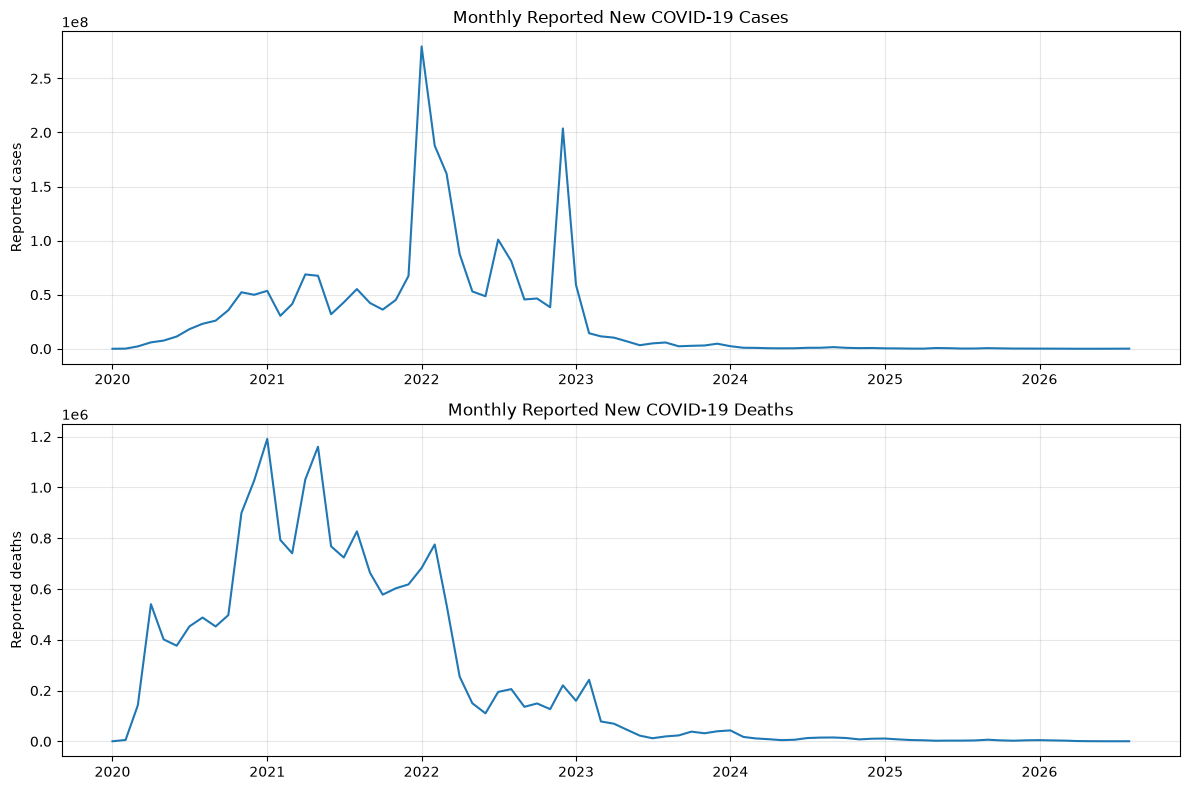

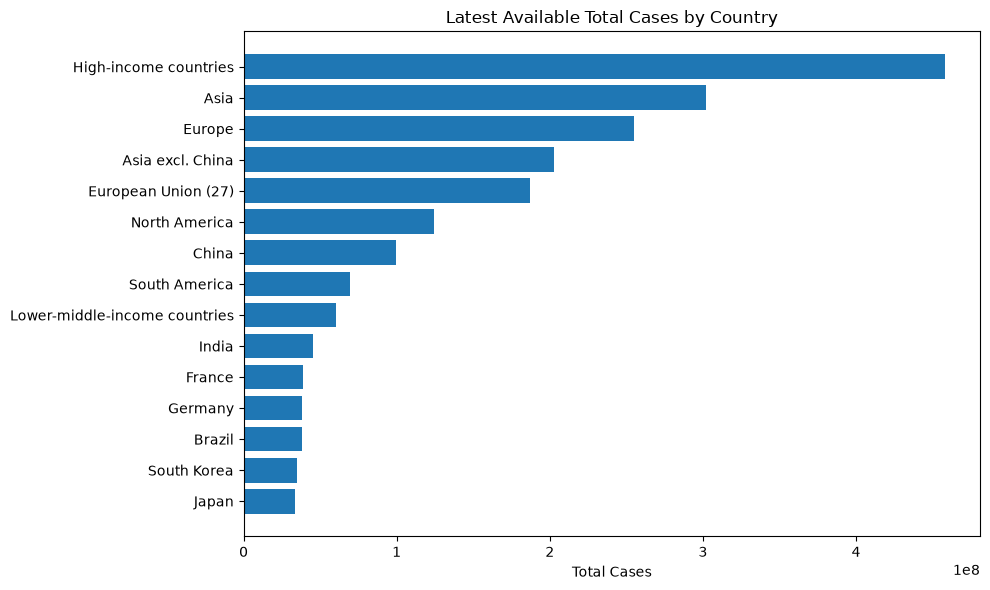

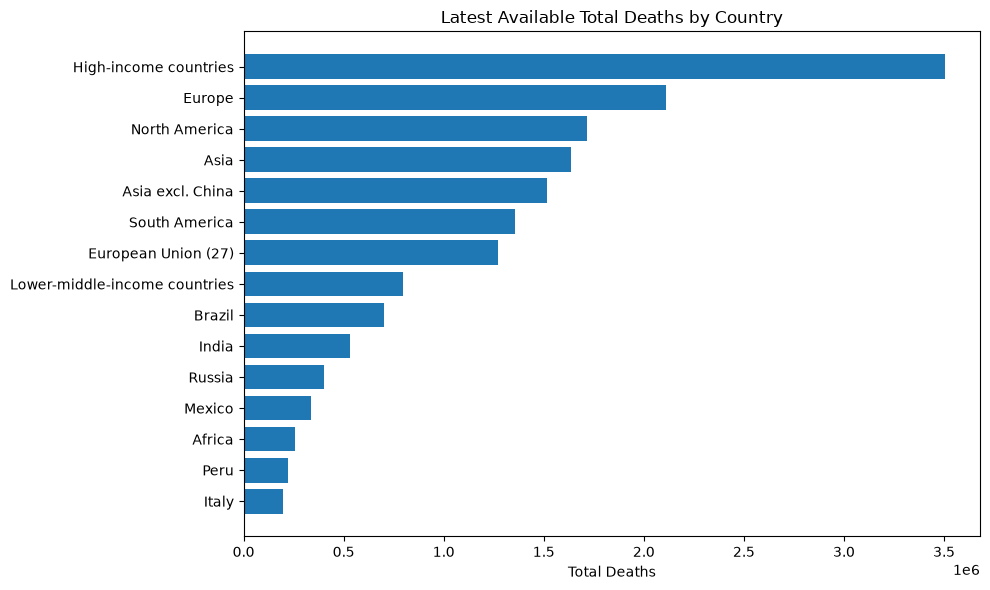


DONE — REPORT FILES CREATED
country_total_cases.png
country_total_deaths.png
missing_values_report.csv
monthly_covid_trends.png
project_summary.csv

Summary:
        Metric      Value
          Rows     538921
       Columns         61
     Countries        227
Duplicate rows          0
 Missing cells   17930406
    First date 2020-01-01
     Last date 2026-08-30


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
P = Path(r"C:\Users\acer\Desktop\COVID-19-Global-Impact-Dashboard")
CLEAN = P / "data" / "processed" / "covid_cleaned.csv"
REPORTS = P / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

# Load data
df = pd.read_csv(CLEAN, low_memory=False)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Save actual data quality reports
df.isna().sum().sort_values(ascending=False).rename(
    "missing_values"
).to_csv(REPORTS / "missing_values_report.csv")

summary = pd.DataFrame({
    "Metric": [
        "Rows", "Columns", "Countries",
        "Duplicate rows", "Missing cells",
        "First date", "Last date"
    ],
    "Value": [
        len(df), len(df.columns), df["country"].nunique(),
        int(df.duplicated().sum()), int(df.isna().sum().sum()),
        str(df["date"].min().date()), str(df["date"].max().date())
    ]
})
summary.to_csv(REPORTS / "project_summary.csv", index=False)

# Monthly global trend (sum country-level daily reported values)
monthly = (
    df.dropna(subset=["date"])
      .groupby(pd.Grouper(key="date", freq="MS"))[
          ["new_cases", "new_deaths"]
      ].sum(min_count=1)
      .reset_index()
)

fig, ax = plt.subplots(2, 1, figsize=(12, 8))
ax[0].plot(monthly["date"], monthly["new_cases"])
ax[0].set_title("Monthly Reported New COVID-19 Cases")
ax[0].set_ylabel("Reported cases")
ax[0].grid(True, alpha=0.3)

ax[1].plot(monthly["date"], monthly["new_deaths"])
ax[1].set_title("Monthly Reported New COVID-19 Deaths")
ax[1].set_ylabel("Reported deaths")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(REPORTS / "monthly_covid_trends.png", dpi=150)
plt.show()
plt.close()

# Countries with highest recorded total cases/deaths
latest = (
    df.sort_values("date")
      .groupby("country", as_index=False)
      .tail(1)
)

for col, title, filename in [
    ("total_cases", "Latest Available Total Cases by Country",
     "country_total_cases.png"),
    ("total_deaths", "Latest Available Total Deaths by Country",
     "country_total_deaths.png")
]:
    top = latest[["country", col]].dropna().nlargest(15, col)
    if not top.empty:
        plt.figure(figsize=(10, 6))
        plt.barh(top["country"][::-1], top[col][::-1])
        plt.title(title)
        plt.xlabel(col.replace("_", " ").title())
        plt.tight_layout()
        plt.savefig(REPORTS / filename, dpi=150)
        plt.show()
        plt.close()

print("\nDONE — REPORT FILES CREATED")
for f in sorted(REPORTS.iterdir()):
    print(f.name)
print("\nSummary:")
print(summary.to_string(index=False))

## Data Quality Notes

- The raw dataset contains 617,667 rows and 61 columns.
- The cleaned dataset contains 538,921 rows and 61 columns.
- The reason for the row-count difference must be verified against the cleaning process.
- The cleaned data contains substantial missing values, so results should be interpreted carefully.

## Key Insights

1. The dataset covers 227 countries/locations.
2. The observed date range is 1 January 2020 to 30 August 2026.
3. The `human_development_index` field is entirely missing in the inspected dataset.
4. Monthly charts show reported COVID-19 cases and deaths over time.
5. Country comparison charts show reported totals, which should be interpreted in light of differences in reporting and missing data.